# Analysis 3 · Realism and extremes: Does the forecast look like real weather?

A forecast can have a low average error and still look unrealistic, for example if it smooths out storms. This notebook checks how realistic the forecasts are and how they behave in unusual weather, the closest we can get to a climate the models have not seen.

**How to use this notebook:** All analyses are ready. Run all cells (or read the exported version).
Every figure has a number. When you check a claim, name the figure that supports or contradicts it.

Data: WeatherBench 2, January 2020, 64×32 grid (about 600 km), ERA5 as reference.
Dashed lines = physics-based models (HRES, IFS ENS). Solid lines = AI or hybrid models.

| Figure | What it shows |
|---|---|
| **3.1** | Activity: are the forecasts smoother than reality? |
| **3.2** | Weather maps side by side |
| **3.3** | Which scales get lost? |
| **3.4** | Errors in normal and in unusual weather |
| **3.5** | Do the models underestimate extremes? |

In [1]:
from wb2_helpers import *
CITY = 'Hannover'            # used for the city figures (see CITIES in wb2_helpers.py)
MAP_DATE = '2020-01-25T00'   # valid time for maps (between 2020-01-08 and 2020-02-07)
col = lambda m: COLORS[m.replace(' (mean)', '').replace(' (member)', '')]
available()

,HRES,GraphCast,Pangu,NeuralGCM,IFS ENS,GenCast,NeuralGCM ENS
2-m temperature (K),✅,✅,✅,—,✅,✅,—
10-m wind speed (m/s),✅,✅,✅,—,✅,✅,—
Z500 (m²/s²),✅,✅,✅,✅,✅,✅,✅


### Figure 3.1 · Activity ratio

*How to read:* How strong the forecast's deviations from the January mean are compared with reality. 1 = as strong as reality, below 1 = smoother. Dotted = a single ensemble member, squares = ensemble mean.

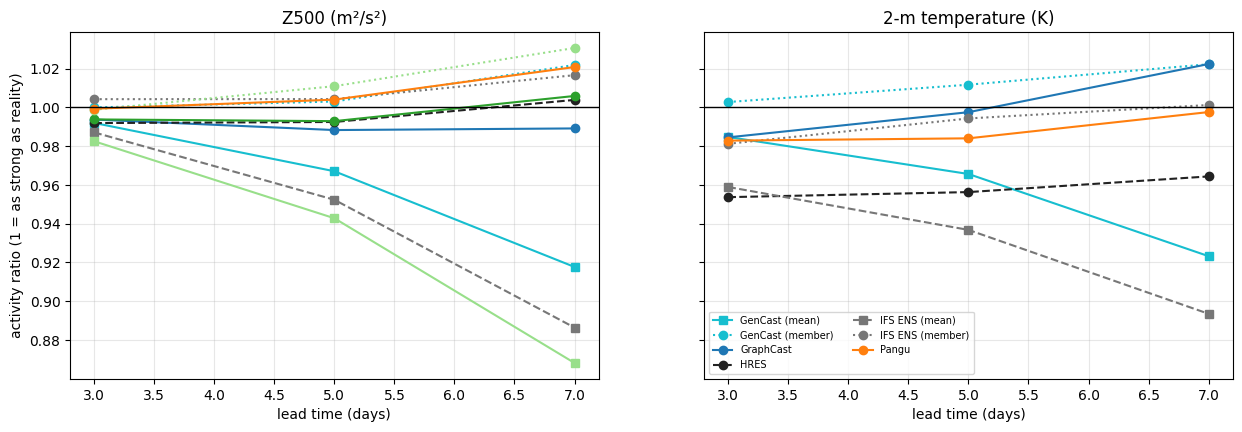

model                GenCast (mean)  GenCast (member)  GraphCast   HRES  \
var            days                                                       
2m_temperature 3              0.985             1.003      0.985  0.954   
               5              0.966             1.012      0.998  0.956   
               7              0.923             1.022      1.022  0.964   
geopotential   3              0.992             1.000      0.994  0.992   
               5              0.967             1.003      0.988  0.992   
               7              0.918             1.022      0.989  1.004   

model                IFS ENS (mean)  IFS ENS (member)  NeuralGCM  \
var            days                                                
2m_temperature 3              0.959             0.981        NaN   
               5              0.937             0.994        NaN   
               7              0.894             1.001        NaN   
geopotential   3              0.987             1.004      0.994   
               5              0.952             1.004      0.993   
               7              0.886             1.017      1.006   

model                NeuralGCM ENS (mean)  NeuralGCM ENS (member)  Pangu  
var            days                                                       
2m_temperature 3                      NaN                     NaN  0.983  
               5                      NaN                     NaN  0.984  
               7                      NaN                     NaN  0.998  
geopotential   3                    0.983                   0.999  0.999  
               5                    0.943                   1.011  1.004  
               7                    0.868                   1.031  1.021

In [2]:
rows = []
for var in ['geopotential', '2m_temperature']:
    for d, l in LEADS.items():
        for m in DET:
            fc, tr = det_forecast(m, var, l)
            if fc is not None: rows.append({'model': m, 'var': var, 'days': d, 'activity': activity_ratio(fc, tr)})
        for m, (n, md) in ENS.items():
            fc, tr = ens_forecast(m, var, l, 50)
            if fc is None: continue
            rows.append({'model': m + ' (member)', 'var': var, 'days': d, 'activity': activity_ratio(fc.isel({md: 0}), tr)})
            rows.append({'model': m + ' (mean)', 'var': var, 'days': d, 'activity': activity_ratio(fc.mean(md), tr)})
actv = pd.DataFrame(rows)
fig, axs = plt.subplots(1, 2, figsize=(15, 4.5), sharey=True)
for a, var in zip(axs, ['geopotential', '2m_temperature']):
    for m, s in actv[actv['var'] == var].groupby('model'):
        base = m.replace(' (mean)', '').replace(' (member)', '')
        ls = ':' if 'member' in m else STYLE[base]
        a.plot(s.days, s.activity, marker='s' if 'mean' in m else 'o', ls=ls, color=COLORS[base], label=m)
    a.axhline(1, color='k', lw=1); a.set_title(VARS[var]); a.set_xlabel('lead time (days)'); a.grid(alpha=.3)
axs[0].set_ylabel('activity ratio (1 = as strong as reality)'); axs[1].legend(fontsize=7, ncol=2)
save(fig, '3.1')
actv.pivot_table(index=['var', 'days'], columns='model', values='activity').round(3)

### Figure 3.2 · Weather maps side by side

*How to read:* Deviation of Z500 from the January mean for one valid time, 7-day forecasts. Red = ridge (high pressure), blue = trough (low pressure).

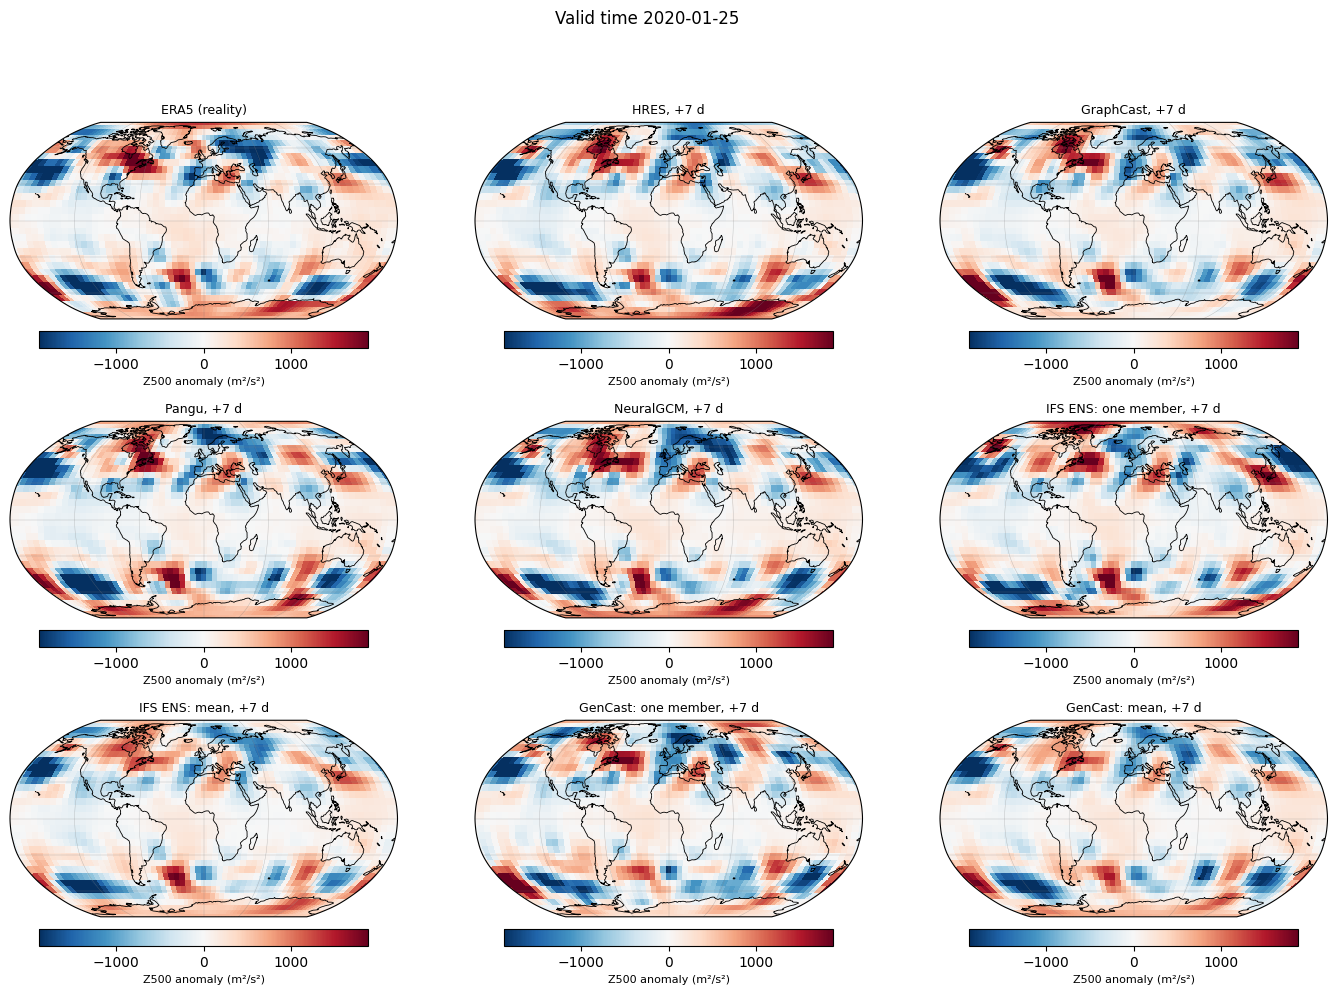

In [3]:
lead = LEADS[7]
panels = {}
fc, tr = det_forecast('HRES', 'geopotential', lead); panels['ERA5 (reality)'] = tr
for m in DET:
    fc, _ = det_forecast(m, 'geopotential', lead); panels[m] = fc
for m in ['IFS ENS', 'GenCast']:
    n, md = ENS[m]; fc, _ = ens_forecast(m, 'geopotential', lead, 50)
    panels[f'{m}: one member'] = fc.isel({md: 0}); panels[f'{m}: mean'] = fc.mean(md)
v = float(abs(anomaly(panels['ERA5 (reality)'].sel(time=MAP_DATE))).quantile(.98))
fig, axs = map_subplots(3, 3, figsize=(17, 11))
for a, (t, f) in zip(axs.flat, panels.items()):
    plot_map(a, anomaly(f.sel(time=MAP_DATE)), t if t.startswith('ERA5') else f'{t}, +7 d', vmin=-v, vmax=v, label='Z500 anomaly (m²/s²)')
plt.suptitle(f'Valid time {MAP_DATE[:10]}', fontsize=12)
save(fig, '3.2')

### Figure 3.3 · Which scales get lost?

*How to read:* Power of Z500 patterns in the northern mid-latitudes (30–70°N) per zonal wavenumber, divided by the power in ERA5, day 7. Wavenumber 1 = one wave around the globe (very large), high wavenumbers = small weather systems. Below 1 = the forecast is weaker than reality at that scale.

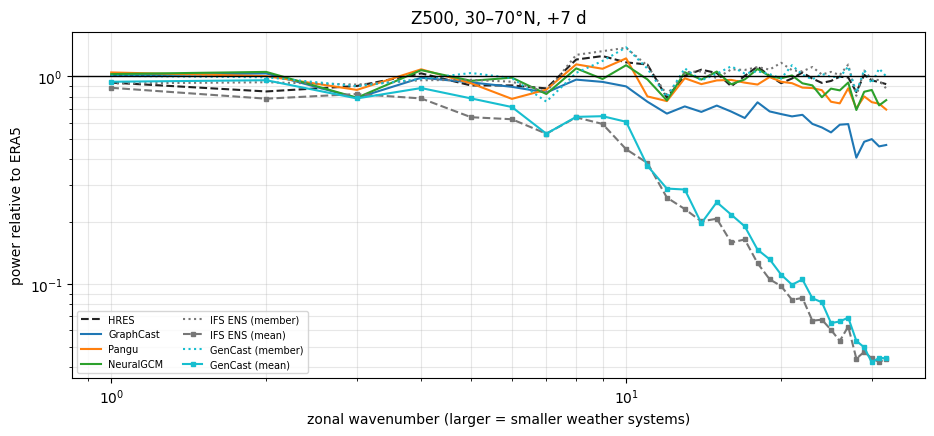

,large (k 1–3),synoptic (k 4–10),small (k > 10)
HRES,0.894,1.050,0.980
GraphCast,0.944,0.922,0.610
Pangu,0.970,1.015,0.854
NeuralGCM,0.956,1.005,0.907
IFS ENS (member),0.926,1.097,1.031
IFS ENS (mean),0.829,0.606,0.120
GenCast (member),0.965,1.052,1.017
GenCast (mean),0.895,0.685,0.136


In [4]:
lead = LEADS[7]
fc, tr = det_forecast('HRES', 'geopotential', lead)
ref = zonal_spectrum(tr)
curves = {}
for m in DET:
    f, _ = det_forecast(m, 'geopotential', lead); curves[m] = zonal_spectrum(f) / ref
for m in ['IFS ENS', 'GenCast']:
    n, md = ENS[m]; f, _ = ens_forecast(m, 'geopotential', lead, 50)
    curves[f'{m} (member)'] = zonal_spectrum(f.isel({md: 0})) / ref
    curves[f'{m} (mean)'] = zonal_spectrum(f.mean(md)) / ref
k = np.arange(1, len(ref) + 1)
fig, ax = plt.subplots(figsize=(11, 4.5))
for m, c in curves.items():
    base = m.replace(' (mean)', '').replace(' (member)', '')
    ax.plot(k, c, ls=':' if 'member' in m else STYLE[base], marker='s' if 'mean' in m else None, ms=3, color=COLORS[base], label=m)
ax.axhline(1, color='k', lw=1); ax.set_xscale('log'); ax.set_yscale('log')
ax.set_xlabel('zonal wavenumber (larger = smaller weather systems)'); ax.set_ylabel('power relative to ERA5')
ax.set_title('Z500, 30–70°N, +7 d'); ax.grid(alpha=.3, which='both'); ax.legend(fontsize=7, ncol=2)
save(fig, '3.3')
pd.DataFrame({m: [c[:3].mean(), c[3:10].mean(), c[10:].mean()] for m, c in curves.items()},
             index=['large (k 1–3)', 'synoptic (k 4–10)', 'small (k > 10)']).T.round(3)

### Figure 3.4 · Errors in normal and in unusual weather

*How to read:* All grid points and times are sorted by how far the real 2-m temperature was from the January mean. RMSE in each class at day 5. The right-most class contains the 5 % most unusual situations.

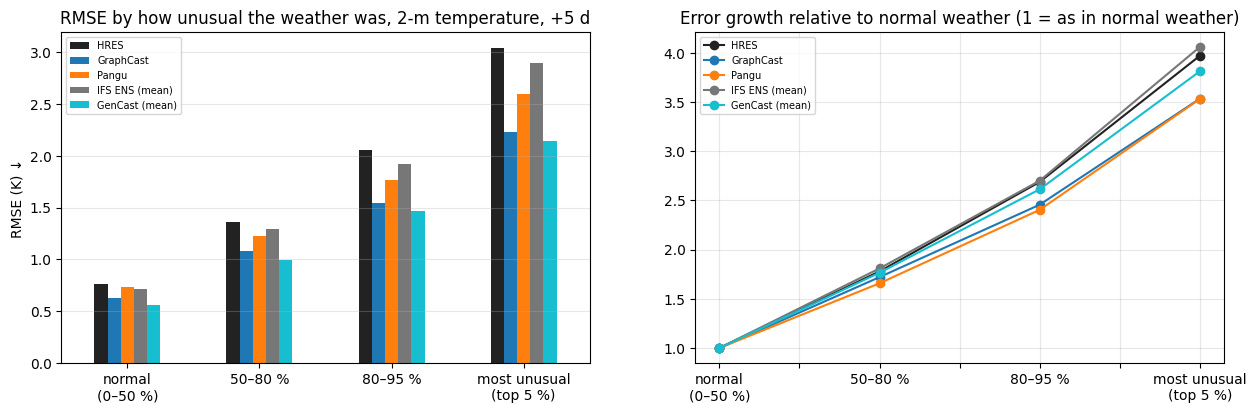

,HRES,GraphCast,Pangu,IFS ENS (mean),GenCast (mean)
normal\n(0–50 %),0.77,0.63,0.74,0.71,0.56
50–80 %,1.36,1.08,1.22,1.29,0.99
80–95 %,2.06,1.55,1.77,1.92,1.47
most unusual\n(top 5 %),3.04,2.22,2.60,2.89,2.14


In [5]:
CLASSES = [(0, .5, 'normal\n(0–50 %)'), (.5, .8, '50–80 %'), (.8, .95, '80–95 %'), (.95, 1.0, 'most unusual\n(top 5 %)')]
VAR = '2m_temperature'
lead = LEADS[5]
_, tr0 = det_forecast('HRES', VAR, lead)
abs_anom = abs(anomaly(tr0))
qs = [float(abs_anom.quantile(q)) for q in [0, .5, .8, .95, 1.0]]
def by_class(fc, tr):
    a = abs(anomaly(tr)); w = np.cos(np.deg2rad(tr.latitude)) * xr.ones_like(tr)
    out = []
    for (lo, hi, _), qlo, qhi in zip(CLASSES, qs[:-1], qs[1:]):
        m = (a >= qlo) & (a <= qhi)
        out.append(float(np.sqrt((((fc - tr) ** 2) * w).where(m).sum() / w.where(m).sum())))
    return out
rows = {}
for m in DET:
    fc, tr = det_forecast(m, VAR, lead)
    if fc is not None: rows[m] = by_class(fc, tr)
for m in ['IFS ENS', 'GenCast']:
    n, md = ENS[m]; fc, tr = ens_forecast(m, VAR, lead, 50); rows[m + ' (mean)'] = by_class(fc.mean(md), tr)
cls = pd.DataFrame(rows, index=[c[2] for c in CLASSES])
fig, axs = plt.subplots(1, 2, figsize=(15, 4.3))
cls.plot.bar(ax=axs[0], rot=0, color=[col(m) for m in cls.columns]); axs[0].set_ylabel('RMSE (K) ↓')
axs[0].set_title('RMSE by how unusual the weather was, 2-m temperature, +5 d'); axs[0].grid(alpha=.3, axis='y')
(cls / cls.iloc[0]).plot(ax=axs[1], marker='o', color=[col(m) for m in cls.columns])
axs[1].set_title('Error growth relative to normal weather (1 = as in normal weather)'); axs[1].grid(alpha=.3)
for a in axs: a.legend(fontsize=7)
save(fig, '3.4')
cls.round(2)

### Figure 3.5 · Do the models underestimate extremes?

*How to read:* For the 5 % most unusual situations: how large was the forecast deviation from the January mean, compared with the real deviation? 1 = the full strength of the extreme was predicted, below 1 = it was underestimated.

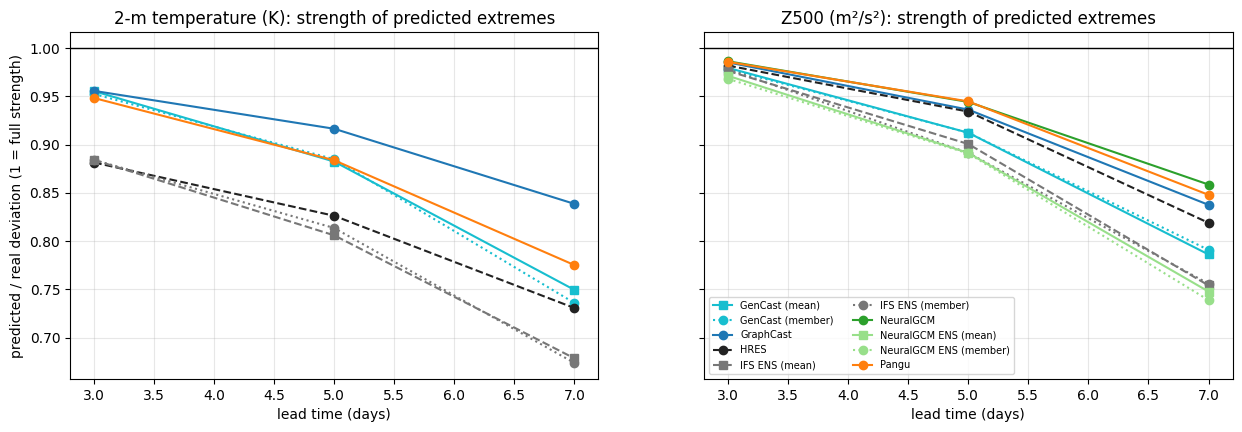

model                GenCast (mean)  GenCast (member)  GraphCast   HRES  \
var            days                                                       
2m_temperature 3              0.955             0.952      0.956  0.881   
               5              0.882             0.885      0.916  0.826   
               7              0.749             0.736      0.839  0.731   
geopotential   3              0.979             0.978      0.985  0.982   
               5              0.912             0.912      0.936  0.934   
               7              0.786             0.791      0.838  0.819   

model                IFS ENS (mean)  IFS ENS (member)  NeuralGCM  \
var            days                                                
2m_temperature 3              0.884             0.884        NaN   
               5              0.806             0.814        NaN   
               7              0.679             0.674        NaN   
geopotential   3              0.976             0.978      0.986   
               5              0.901             0.891      0.944   
               7              0.754             0.756      0.859   

model                NeuralGCM ENS (mean)  NeuralGCM ENS (member)  Pangu  
var            days                                                       
2m_temperature 3                      NaN                     NaN  0.948  
               5                      NaN                     NaN  0.884  
               7                      NaN                     NaN  0.775  
geopotential   3                    0.971                   0.968  0.986  
               5                    0.891                   0.891  0.945  
               7                    0.748                   0.739  0.848

In [6]:
rows = []
for var in ['2m_temperature', 'geopotential']:
    for d, l in LEADS.items():
        _, tr0 = det_forecast('HRES', var, l)
        thr = float(abs(anomaly(tr0)).quantile(.95))
        def amp(fc, tr):
            ao, af = anomaly(tr), anomaly(fc)
            m = abs(ao) >= thr
            return float((af * np.sign(ao)).where(m).mean() / abs(ao).where(m).mean())
        for m in DET:
            fc, tr = det_forecast(m, var, l)
            if fc is not None: rows.append({'model': m, 'var': var, 'days': d, 'amplitude': amp(fc, tr)})
        for m, (n, md) in ENS.items():
            fc, tr = ens_forecast(m, var, l, 50)
            if fc is None: continue
            rows.append({'model': m + ' (member)', 'var': var, 'days': d, 'amplitude': amp(fc.isel({md: 0}), tr)})
            rows.append({'model': m + ' (mean)', 'var': var, 'days': d, 'amplitude': amp(fc.mean(md), tr)})
ampl = pd.DataFrame(rows)
fig, axs = plt.subplots(1, 2, figsize=(15, 4.5), sharey=True)
for a, var in zip(axs, ['2m_temperature', 'geopotential']):
    for m, s in ampl[ampl['var'] == var].groupby('model'):
        base = m.replace(' (mean)', '').replace(' (member)', '')
        a.plot(s.days, s.amplitude, marker='s' if 'mean' in m else 'o', ls=':' if 'member' in m else STYLE[base], color=COLORS[base], label=m)
    a.axhline(1, color='k', lw=1); a.set_title(f'{VARS[var]}: strength of predicted extremes'); a.set_xlabel('lead time (days)'); a.grid(alpha=.3)
axs[0].set_ylabel('predicted / real deviation (1 = full strength)'); axs[1].legend(fontsize=7, ncol=2)
save(fig, '3.5')
ampl.pivot_table(index=['var', 'days'], columns='model', values='amplitude').round(3)